      OVERALL MODEL ACCURACY: 88.44%

--- DETAILED METRICS (PRECISION, RECALL, F1-SCORE) ---
                     precision    recall  f1-score       support
actinic keratosis     0.870504  0.746914  0.803987    162.000000
acute bronchiolitis   0.955947  0.900415  0.927350    241.000000
acute bronchitis      0.804444  0.744856  0.773504    243.000000
acute bronchospasm    0.611702  0.709877  0.657143    162.000000
acute kidney injury   0.969697  0.987654  0.978593    162.000000
...                        ...       ...       ...           ...
vaginitis             0.969136  0.957317  0.963190    164.000000
vulvodynia            0.899598  0.918033  0.908722    244.000000
accuracy              0.884379  0.884379  0.884379      0.884379
macro avg             0.885251  0.884959  0.884214  19218.000000
weighted avg          0.888378  0.884379  0.885513  19218.000000

[103 rows x 4 columns]

[SUCCESS] Detailed metrics saved to 'model_metrics_detailed.csv'


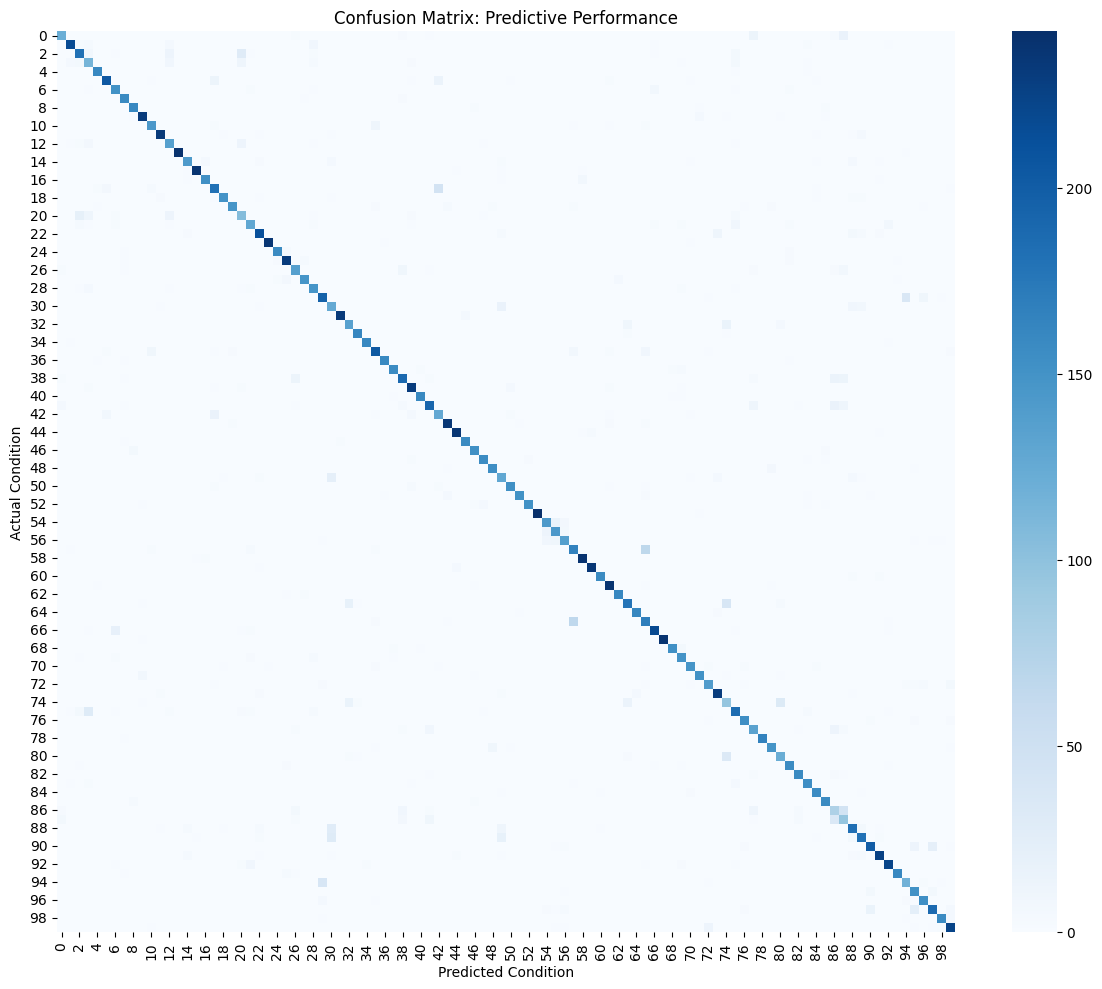

In [7]:
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Define Paths
DATA_PATH = r"D:\disease-predictor\backend\data\Diseases_and_Symptoms_dataset.csv"
MODEL_PATH = r"D:\disease-predictor\backend\artifacts\xgboost_model.pkl"

# 2. Load Data
data = pd.read_csv(DATA_PATH)
X = data.drop(columns=['diseases']) 
y = data['diseases']

# 3. Encode Labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Split Data (Ensure this matches your training split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 5. Load Trained Model
with open(MODEL_PATH, 'rb') as f:
    model = pickle.load(f)

# 6. Generate Predictions
y_pred = model.predict(X_test)

# --- COMPREHENSIVE METRICS REPORT ---

# A. Overall Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"==========================================")
print(f"      OVERALL MODEL ACCURACY: {acc*100:.2f}%")
print(f"==========================================")

# B. Detailed Metrics (Precision, Recall, F1-Score)
# We use output_dict=True to make it a clean table
report_dict = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
df_report = pd.DataFrame(report_dict).transpose()

print("\n--- DETAILED METRICS (PRECISION, RECALL, F1-SCORE) ---")
# Using print() to show it directly in the notebook for your presentation
print(df_report)

# Export for your project documentation
df_report.to_csv("model_metrics_detailed.csv")
print("\n[SUCCESS] Detailed metrics saved to 'model_metrics_detailed.csv'")

# C. Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, cmap='Blues')
plt.title('Confusion Matrix: Predictive Performance')
plt.ylabel('Actual Condition')
plt.xlabel('Predicted Condition')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()